# Heston model: Fourier (SINC) pricing and Monte Carlo simulation

Prices a European put/call and four digital options (cash-or-nothing and asset-or-nothing) under the Heston model with a Fourier/SINC method, then checks the prices against Monte Carlo simulation (exact CIR variance sampling and Andersen's QE scheme) through the martingale property. See the README for a summary of the results.

Equation references (e.g. *Lec. D.11*) point to the Computational Finance course notes, University of Bologna.

In [ ]:
import numpy as np
import pandas as pd
# from tqdm.notebook import tqdm
from scipy.stats import norm as scipy_norm
import matplotlib.pyplot as plt
import seaborn as sns

In [50]:
plt.style.use("seaborn-v0_8")
plt.rcParams['figure.figsize'] = (20, 5)
plt.rcParams['grid.color'] = "#B0B0B0"
plt.rcParams['grid.linewidth'] = 0.5
plt.rcParams.update({"axes.grid" : True})

for param in ['text.color', 'axes.labelcolor', 'xtick.color', 'ytick.color']:
    plt.rcParams[param] = "#0e0e0e"

for param in ['figure.facecolor', 'axes.facecolor', 'savefig.facecolor']:
    plt.rcParams[param] = "#f8f8f8" 

colors = [
    "#248dd3", 
    "#27a66d", 
    "#d52c2d",
    "#ffd800",
    "#7038b0",
    "#ff468d",
    "#1ae4d4",
    "#fa7034",
    "#ffffff",
]

sns.set_palette(colors)

# Params

In [ ]:
# Heston model parameters (Table 1)
lam = 1.03179746   # mean reversion speed
nu_bar = 0.07819284   # long-run variance
eta = 1.0 # vol of vol
nu0 = 0.04 # initial variance
rho = -0.6450755   # spot-vol correlation

# Market parameters
S0 = 1.2
K = 1.2
T = 1.0
r = 0.0    # risk free rate = 0 as an assumption (according to problem statement)

# Simulation parameters 
N_traj = 100000
N_steps = 252
N_months = 12
dt = T / N_steps
step_per_month = N_steps // N_months
t_months = np.arange(1, 13) / 12
option_names = ["Put", "Call", "Pcn", "Pan", "Ccn", "Can"]

# Fourier + CF + SINC

In [4]:
def heston_cf(u, t, lam, nu_bar, eta, nu0, rho):
    """
    CF of X_T = log(S_T / S0) under Heston.
    phi(u) = E[exp(i * 2 * pi * u * X_T)] = exp(A - nu0 * B)
    Source: Appendix L (lectures), eq. L.2 - L.4
    Closed form via complex CIR: Appendix D, eq. D.11 - D.12
    
    # Reduces to E[exp(-Lambda * int(nu dt))] over complex CIR
    # Solved via general affine/CIR ODE system, Appendix C eq. C.8 - C.9
    # with f = Lambda, boundary conditions A(T, T) = B(T, T) = 0
    """
    v = 1j * 2 * np.pi * u
    kap = lam - rho * eta * v    # Lec. L.3
    Lam = 0.5 * v - 0.5 * v ** 2    # Lec. L.4
    gam = np.sqrt(kap ** 2 + 2 * Lam * eta ** 2)    # Lec. D.11
    g = (gam - kap) / (gam + kap)
    zp = (gam - kap) / eta ** 2
    egt = np.exp(-gam * t)
    B = zp * (1 - egt) / (1 + g * egt)    # Lec. D.11
    C = 2 * np.log((1 + g) / (1 + g * egt)) / eta ** 2
    A = lam * nu_bar * (C - zp * t)    # Lec. D.12
    return np.exp(A - nu0 * B)

# Sanity checks 
phi0 = heston_cf(0.0, T, lam, nu_bar, eta, nu0, rho)
u_test = np.linspace(-10, 10, 1000)
phi_arr = heston_cf(u_test, T, lam, nu_bar, eta, nu0, rho)
u_pos = np.array([0.5, 1.0, 2.0])
conj_err = np.max(np.abs(
    heston_cf(u_pos,  T, lam, nu_bar, eta, nu0, rho) -
    np.conj(heston_cf(-u_pos, T, lam, nu_bar, eta, nu0, rho))
))
print(f"phi(0) = {phi0:.6f} (expected: 1.0)")
print(f"max|phi(u)| = {np.max(np.abs(phi_arr)):.6f} (expected: <= 1.0)")
print(f"Conj check = {conj_err:.2e} (expected: ~ 0)")

phi(0) = 1.000000+0.000000j (expected: 1.0)
max|phi(u)| = 0.999865 (expected: <= 1.0)
Conj check = 0.00e+00 (expected: ~ 0)


In [ ]:
def pr_x_lt_w_vec(cf_func, Xc, w_arr, off, tau):
    """
    P(X_T < w) via SINC series, vectorized over w_arr
    SINC (Fourier-sine) series expansion, truncated when the relative term size < 1e-8
    off = 0 -> risk-neutral measure (P_cn)
    off = -1j / (2 * pi) -> asset measure (P_an)
    """
    total = np.zeros(len(w_arr))
    m = 1
    while True:
        u = m / (2 * Xc) + off
        phi = cf_func(u, tau)    # scalar CF
        th = np.pi * m * w_arr / Xc    # shape (N_traj, )
        delta = (np.cos(th) * phi.imag - np.sin(th) * phi.real) / m
        total += delta
        if np.max(np.abs(delta / (total + 1e-300))) < 1e-8:
            break
        m += 2
    return 0.5 - 2.0 * total / np.pi


def price_options_vec(S_val, nu_val, tau, lam, nu_bar, eta, rho, K, Xc):
    """
    Price all 6 options vectorized over trajectories
    Each trajectory has its own spot S_val and variance nu_val
    Source: Appendix A eq. A.14 - A.17 (lectures)
    """
    w = np.log(K / S_val)

    # Decompose CF: phi = exp(A(u,tau) - nu_val * B(u,tau))
    # A, B don't depend on nu => precompute per SINC node, apply to all trajectories
    
    results = {}
    for off, key in [(0.0, "Pcn"), (-1j / (2 * np.pi), "Pan")]:
        
        m = 1
        total = np.zeros(len(S_val))
        
        while True:
            u = m / (2 * Xc) + off
            v = 1j * 2 * np.pi * u
            kap = lam - rho * eta * v
            Lam = 0.5 * v - 0.5 * v ** 2
            gam = np.sqrt(kap ** 2 + 2 * Lam * eta ** 2)
            g = (gam - kap) / (gam + kap)
            zp = (gam - kap) / eta ** 2
            egt = np.exp(-gam * tau)
            B = zp * (1 - egt) / (1 + g * egt)
            C = 2 * np.log((1 + g) / (1 + g * egt)) / eta ** 2
            A = lam * nu_bar * (C - zp * tau)
            phi = np.exp(A - nu_val * B)    # shape (N_traj, )
            th = np.pi * m * w / Xc
            delta = (np.cos(th) * phi.imag - np.sin(th) * phi.real) / m
            total += delta
            
            if np.max(np.abs(delta / (total + 1e-300))) < 1e-8:
                break
            
            m += 2
            
        results[key] = 0.5 - 2.0 * total / np.pi

    Pcn = results["Pcn"]
    Pan = results["Pan"]
    Put  = K * Pcn - S_val * Pan
    Call = Put + S_val - K    # put / call parity, r = 0
    return {"Put": Put, "Call": Call, "Pcn": Pcn, "Pan": Pan * S_val, "Ccn": 1 - Pcn, "Can": S_val * (1 - Pan)}


# Cutoff 
Xc = 10 * np.sqrt(nu_bar * T)    # or just Xc = 5, whatever
print(f"Xc = {Xc:.4f}")

#  Reference prices at t = 0 
ref = price_options_vec(np.array([S0]), np.array([nu0]), T, lam, nu_bar, eta, rho, K, Xc)
ref_prices = {name: ref[name][0] for name in option_names}

# Put / call parity check
print(f"\nReference Fourier prices at t = 0 (S0 = K = {S0}, r = 0):")
for name in option_names:
    print(f"{name}: {ref_prices[name]:.6f}")
print(f"\nCall - Put = {ref_prices['Call'] - ref_prices['Put']:.2e} (expected: 0)")
print(f"Pcn + Ccn = {ref_prices['Pcn'] + ref_prices['Ccn']:.6f} (expected: 1)")
print(f"Pan + Can = {ref_prices['Pan'] + ref_prices['Can']:.6f} (expected: S0 = {S0})")

Xc = 2.7963

Reference Fourier prices at t = 0 (S0 = K = 1.2, r = 0):
Put: 0.082747
Call: 0.082747
Pcn: 0.392665
Pan: 0.388450
Ccn: 0.607335
Can: 0.811550

Call - Put = -1.11e-16 (expected: 0)
Pcn + Ccn = 1.000000 (expected: 1)
Pan + Can = 1.200000 (expected: S0 = 1.2)


# Monte Carlo

In [ ]:
def cir_exact_step(nu_prev, dt, lam, nu_bar, eta, rng):
    """
    Exact CIR transition via noncentral chi-squared.
    Sampled exactly: nu_{t+dt} = c * chi'^2_d(lambda), with c, d and lambda below
    """
    df = 4 * lam * nu_bar / eta ** 2
    rho_cir = (eta ** 2 / (4 * lam)) * (1 - np.exp(-lam * dt))
    M2 = np.exp(-lam * dt) / rho_cir
    nc = nu_prev * M2
    return rho_cir * rng.noncentral_chisquare(df, nc)

def simulate_heston(nu0, lam, nu_bar, eta, rho, S0, dt, N_steps, N_traj, rng):
    """
    Simulate Heston paths using exact CIR for nu and eq. 12.18 (lectures) for S.
    Returns nu (N_steps + 1, N_traj), I (N_steps + 1, N_traj), S (N_steps + 1, N_traj)
    """
    nu = np.zeros((N_steps + 1, N_traj))
    I = np.zeros((N_steps + 1, N_traj))
    S = np.zeros((N_steps + 1, N_traj))
    nu[0] = nu0
    S[0] = S0

    xi_Z = rng.standard_normal((N_steps, N_traj))

    for n in range(N_steps):
        nu[n + 1] = cir_exact_step(nu[n], dt, lam, nu_bar, eta, rng)
        I[n + 1] = I[n] + 0.5 * (nu[n] + nu[n + 1]) * dt
        DI = I[n + 1] - I[n]
        d_nu = nu[n + 1] - nu[n]
        X = (-0.5 * DI + (rho / eta)*(d_nu - lam * (nu_bar * dt - DI)) + np.sqrt(np.maximum((1 - rho ** 2) * DI, 0.0)) * xi_Z[n])
        S[n + 1] = S[n] * np.exp(X)

    return nu, I, S

rng = np.random.default_rng(seed = 42)
nu_sim, I_sim, S_sim = simulate_heston(nu0, lam, nu_bar, eta, rho, S0, dt, N_steps, N_traj, rng)

# Martingale check E[S(t_j)] = S0
print("Martingale check E[S(t_j)] (expected S0 = 1.2):")
for j, tm in enumerate(t_months):
    idx = (j + 1) * step_per_month
    mean = S_sim[idx].mean()
    std = S_sim[idx].std() / np.sqrt(N_traj)
    print(f"t = {tm:.2f}: {mean:.4f} +/- {2 * std:.4f}")

Martingale check E[S(t_j)] (expected S0 = 1.2):
t = 0.08: 1.2000 +/- 0.0004
t = 0.17: 1.2001 +/- 0.0006
t = 0.25: 1.1999 +/- 0.0008
t = 0.33: 1.1999 +/- 0.0009
t = 0.42: 1.1996 +/- 0.0010
t = 0.50: 1.1998 +/- 0.0011
t = 0.58: 1.1994 +/- 0.0011
t = 0.67: 1.1995 +/- 0.0012
t = 0.75: 1.1995 +/- 0.0013
t = 0.83: 1.1997 +/- 0.0014
t = 0.92: 1.2001 +/- 0.0014
t = 1.00: 1.2002 +/- 0.0015


In [7]:
results = {name: np.zeros((N_months, N_traj)) for name in option_names}

for j, tm in enumerate(t_months):
    idx = (j + 1) * step_per_month
    tau = T - tm
    S_j = S_sim[idx]
    nu_j = nu_sim[idx]

    if tau < 1e-8:
        results["Put"][j] = np.maximum(K - S_j, 0)
        results["Call"][j] = np.maximum(S_j - K, 0)
        results["Pcn"][j] = (S_j < K).astype(float)
        results["Pan"][j] = (S_j < K) * S_j
        results["Ccn"][j] = (S_j > K).astype(float)
        results["Can"][j] = (S_j > K) * S_j
    else:
        res = price_options_vec(S_j, nu_j, tau, lam, nu_bar, eta, rho, K, Xc)
        for name in option_names:
            results[name][j] = res[name]

    print(f"t = {tm:.2f}, tau = {tau:.2f} done")

t = 0.08, tau = 0.92 done
t = 0.17, tau = 0.83 done
t = 0.25, tau = 0.75 done
t = 0.33, tau = 0.67 done
t = 0.42, tau = 0.58 done
t = 0.50, tau = 0.50 done
t = 0.58, tau = 0.42 done
t = 0.67, tau = 0.33 done
t = 0.75, tau = 0.25 done
t = 0.83, tau = 0.17 done
t = 0.92, tau = 0.08 done
t = 1.00, tau = 0.00 done


In [ ]:
# Martingale check for all options
rows = []
for j, tm in enumerate(t_months):
    row = {"t": tm}
    for name in option_names:
        mean = results[name][j].mean()
        std = results[name][j].std() / np.sqrt(N_traj)
        row[f"{name}_mean"] = mean
        row[f"{name}_std2"] = 2 * std
        row[f"{name}_nsig"] = (mean - ref_prices[name]) / std
    rows.append(row)

df_martingale = pd.DataFrame(rows)

# Print summary for Put
print("Martingale check — Put:")
print(f"Reference: {ref_prices['Put']:.6f}")
for j, tm in enumerate(t_months):
    mean = df_martingale.loc[j, "Put_mean"]
    std2 = df_martingale.loc[j, "Put_std2"]
    nsig = df_martingale.loc[j, "Put_nsig"]
    print(f"t = {tm:.2f}: {mean:.6f} +/- {std2:.6f}  ({nsig:+.1f}σ)")

df_martingale.to_csv("martingale_results.csv", index = False)

Martingale check — Put:
Reference: 0.082747
t = 0.08: 0.082798 +/- 0.000308  (+0.3σ)
t = 0.17: 0.082828 +/- 0.000436  (+0.4σ)
t = 0.25: 0.083019 +/- 0.000535  (+1.0σ)
t = 0.33: 0.082941 +/- 0.000617  (+0.6σ)
t = 0.42: 0.083184 +/- 0.000691  (+1.3σ)
t = 0.50: 0.083090 +/- 0.000757  (+0.9σ)
t = 0.58: 0.083250 +/- 0.000818  (+1.2σ)
t = 0.67: 0.083160 +/- 0.000874  (+0.9σ)
t = 0.75: 0.083119 +/- 0.000926  (+0.8σ)
t = 0.83: 0.083023 +/- 0.000976  (+0.6σ)
t = 0.92: 0.082868 +/- 0.001024  (+0.2σ)
t = 1.00: 0.082870 +/- 0.001075  (+0.2σ)


# Figures

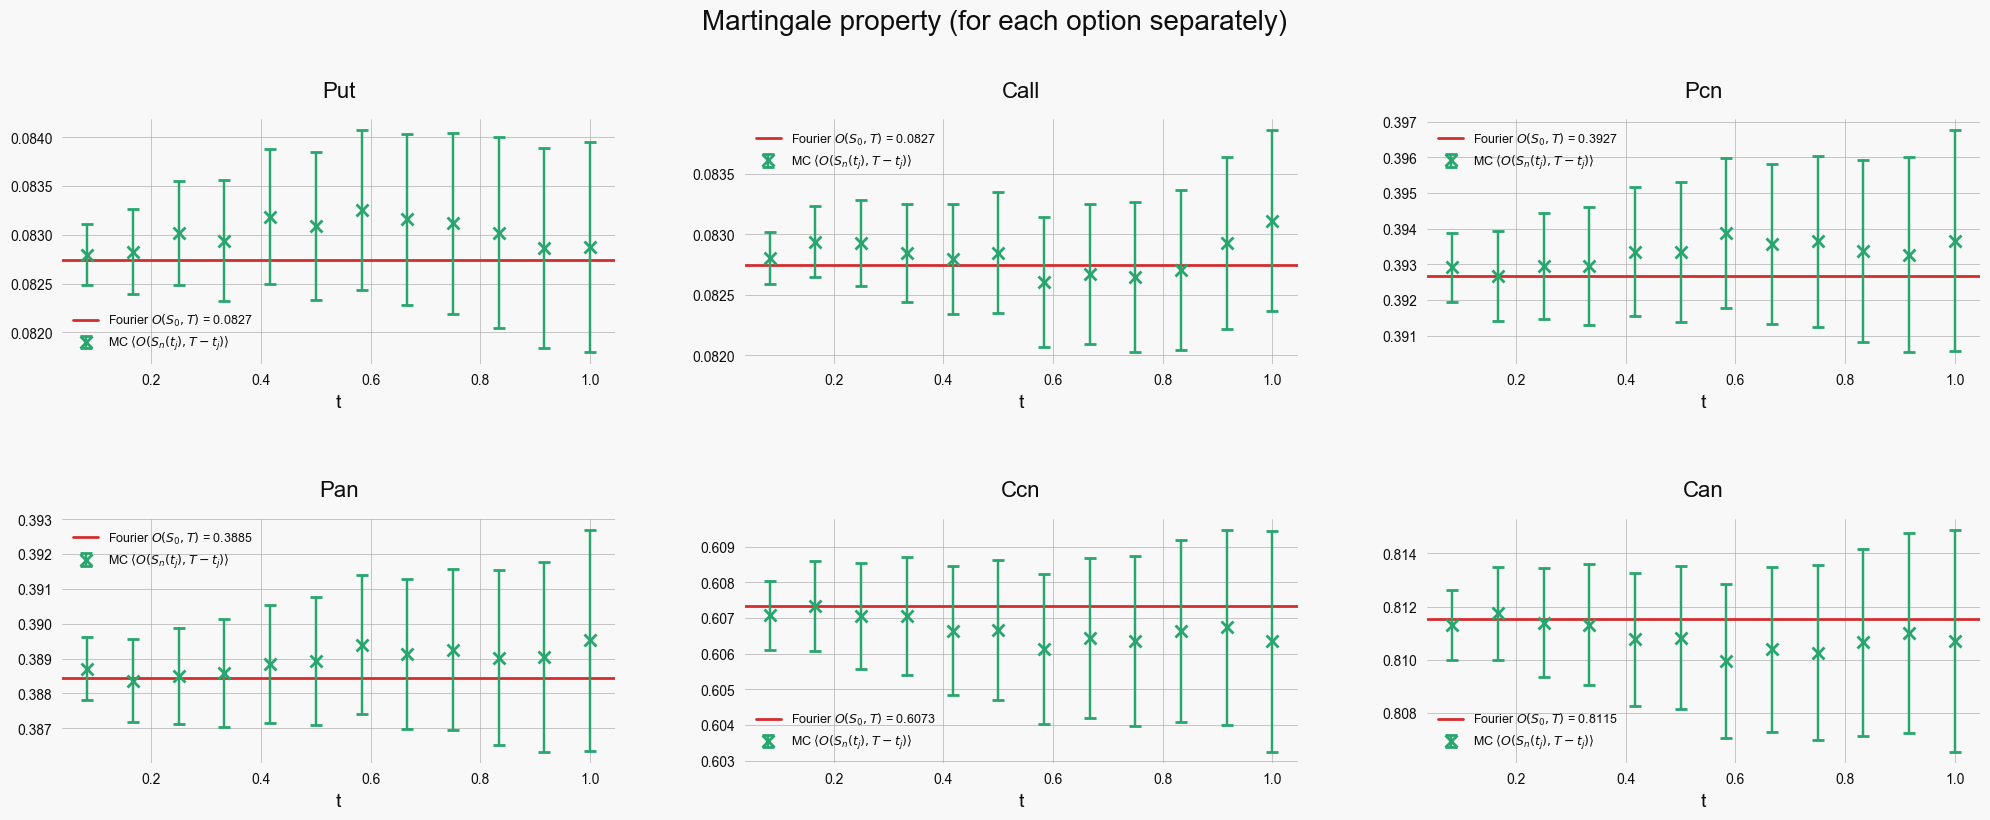

In [46]:
fig, axes = plt.subplots(2, 3, figsize = (20, 8))
axes = axes.flatten()

for i, name in enumerate(option_names):
    ax  = axes[i]
    ref = ref_prices[name]
    means = df_martingale[f"{name}_mean"].values
    stds2 = df_martingale[f"{name}_std2"].values

    ax.axhline(ref, color = colors[2], lw = 2, label = f'Fourier $O(S_0,T)$ = {ref:.4f}')
    ax.errorbar(t_months, means, yerr=stds2, fmt = 'x', color = colors[1], capsize = 4, markersize = 8, markeredgewidth = 2, label = r'MC $\langle O(S_n(t_j), T-t_j) \rangle$')
    ax.set_title(name, fontsize = 16, pad = 16)
    ax.set_xlabel('t', fontsize = 14)
    ax.legend(fontsize = 9)

plt.suptitle('Martingale property (for each option separately)', fontsize = 20, y = 1.02)
plt.tight_layout(h_pad = 5, w_pad = 5)
plt.savefig("martingale_options.png", dpi = 150, bbox_inches = 'tight')
plt.show()

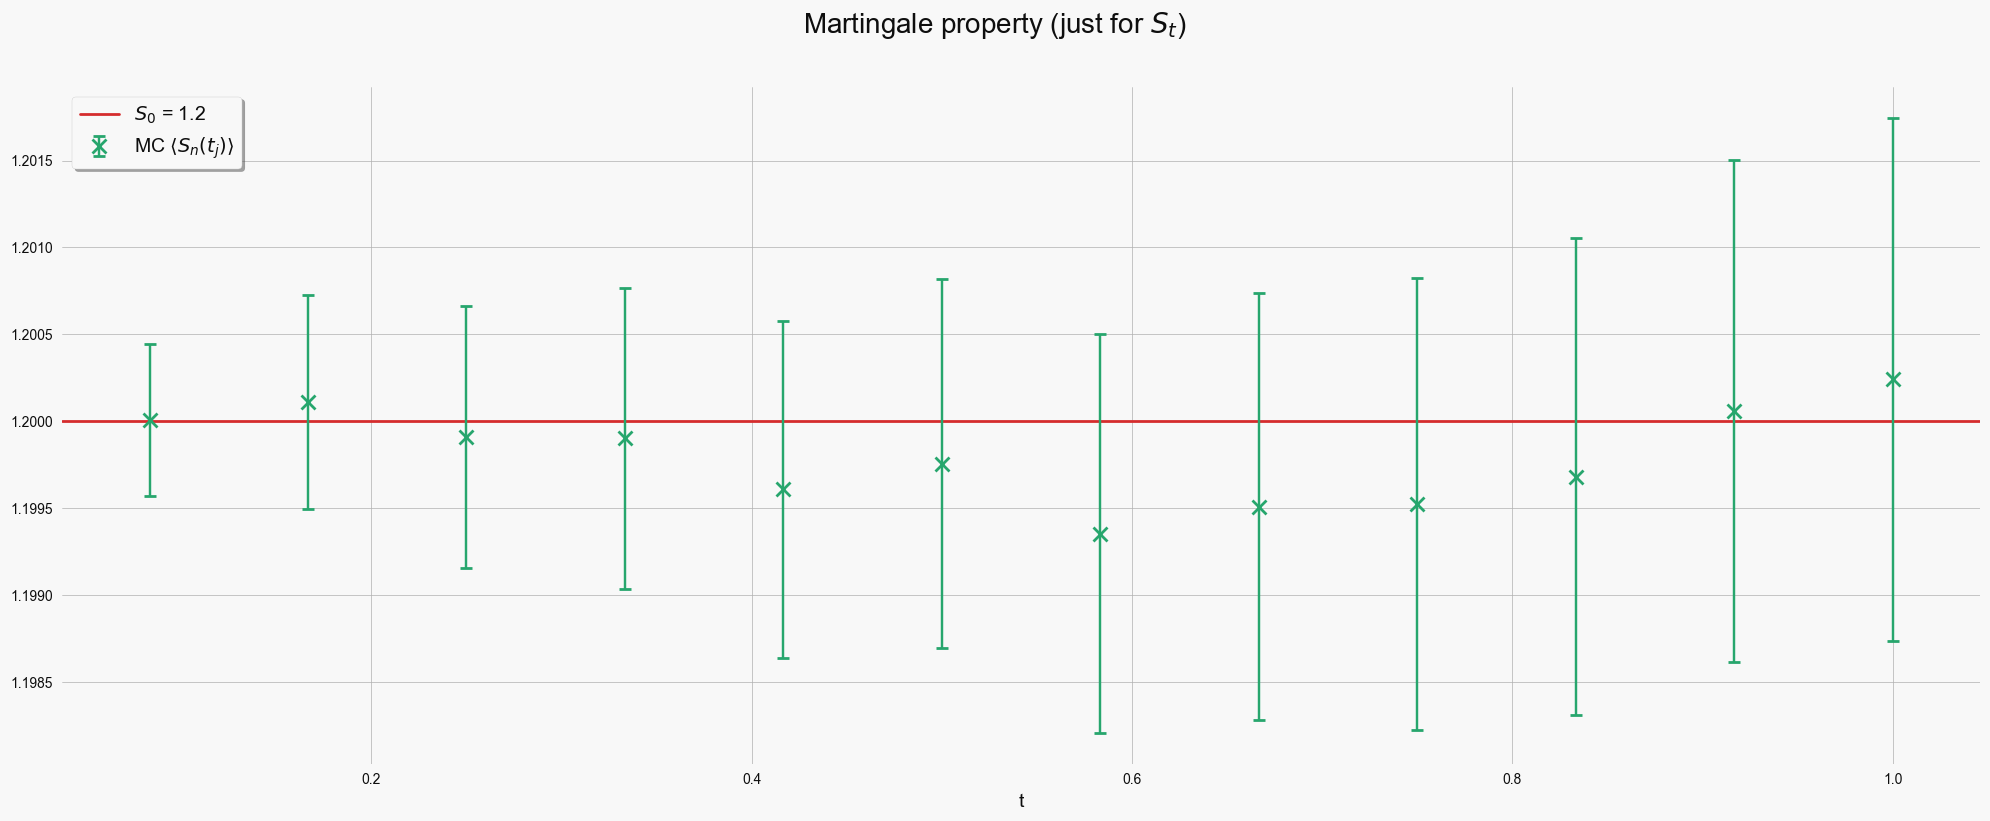

In [45]:
# St martingale separately
fig, ax = plt.subplots(figsize = (20, 8))
means_S = [S_sim[(j + 1) * step_per_month].mean() for j in range(N_months)]
stds_S = [S_sim[(j + 1) * step_per_month].std() / np.sqrt(N_traj) for j in range(N_months)]

ax.axhline(S0, color = colors[2], lw = 2, label = f'$S_0$ = {S0}')
ax.errorbar(t_months, means_S, yerr = 2 * np.array(stds_S), fmt = 'x', color = colors[1], capsize = 4, markersize = 10, markeredgewidth = 2, label = r'MC $\langle S_n(t_j) \rangle$')
ax.set_xlabel('t', fontsize = 14)
ax.legend(fontsize = 14, frameon = True, shadow = True)
plt.suptitle('Martingale property (just for $S_t$)', fontsize = 20, y = 1.02)
plt.tight_layout()
plt.savefig("martingale_St.png", dpi = 150, bbox_inches = 'tight')
plt.show()

# Other checks

In [11]:
# Correlation check 
dX = np.diff(np.log(S_sim), axis = 0)
dnu = np.diff(nu_sim, axis = 0)

corr_per_step = np.array([np.corrcoef(dX[n], dnu[n])[0, 1] for n in range(N_steps)])
emp_corr = corr_per_step.mean()
emp_std = corr_per_step.std() / np.sqrt(N_steps)

print(f"Correlation check:")
print(f"Theoretical: {rho:.4f}")
print(f"Empirical: {emp_corr:.4f} +/- {2*emp_std:.4f}")

Correlation check:
Theoretical: -0.6451
Empirical: -0.6446 +/- 0.0006


In [56]:
# Call via parity vs digitals 
print("Call: parity vs digitals (mean +/- 2 * std):\n")
rows_call = []

for j, tm in enumerate(t_months):
    S_j = S_sim[(j+1)*step_per_month]
    call_parity = results["Put"][j] + S_j - K
    call_digitals = results["Can"][j] - K * results["Ccn"][j]
    mp, sp = call_parity.mean(), call_parity.std() / np.sqrt(N_traj)
    md, sd = call_digitals.mean(), call_digitals.std() / np.sqrt(N_traj)
    better = "parity" if sp < sd else "digitals"
    rows_call.append({"t": tm, "call_parity_mean": mp, "call_parity_std2": 2 * sp, "call_digitals_mean": md, "call_digitals_std2": 2 * sd, "better": better})
    print(f"t = {tm:.2f}: parity = {mp:.5f} +/- {2*sp:.5f}   digitals = {md:.5f} +/- {2*sd:.5f} [{better}]")

df_call = pd.DataFrame(rows_call)

Call: parity vs digitals (mean +/- 2 * std):

t = 0.08: parity = 0.08281 +/- 0.00022   digitals = 0.08281 +/- 0.00022 [digitals]
t = 0.17: parity = 0.08294 +/- 0.00030   digitals = 0.08294 +/- 0.00030 [digitals]
t = 0.25: parity = 0.08293 +/- 0.00035   digitals = 0.08293 +/- 0.00035 [parity]
t = 0.33: parity = 0.08284 +/- 0.00041   digitals = 0.08284 +/- 0.00041 [digitals]
t = 0.42: parity = 0.08279 +/- 0.00045   digitals = 0.08279 +/- 0.00045 [digitals]
t = 0.50: parity = 0.08285 +/- 0.00050   digitals = 0.08285 +/- 0.00050 [digitals]
t = 0.58: parity = 0.08260 +/- 0.00054   digitals = 0.08260 +/- 0.00054 [digitals]
t = 0.67: parity = 0.08267 +/- 0.00058   digitals = 0.08267 +/- 0.00058 [digitals]
t = 0.75: parity = 0.08264 +/- 0.00062   digitals = 0.08264 +/- 0.00062 [digitals]
t = 0.83: parity = 0.08270 +/- 0.00066   digitals = 0.08270 +/- 0.00066 [digitals]
t = 0.92: parity = 0.08293 +/- 0.00071   digitals = 0.08293 +/- 0.00071 [digitals]
t = 1.00: parity = 0.08311 +/- 0.00074   di

In [13]:
summary = {"Option": option_names, "Fourier_price": [ref_prices[n] for n in option_names]}
df_summary = pd.DataFrame(summary)
print("Fourier reference prices at t = 0:\n")
print(df_summary.to_string(index = False))

Fourier reference prices at t = 0:

Option  Fourier_price
   Put       0.082747
  Call       0.082747
   Pcn       0.392665
   Pan       0.388450
   Ccn       0.607335
   Can       0.811550


In [14]:
df_call.to_csv("call_parity_check.csv", index = False)
df_summary.to_csv("fourier_prices.csv", index = False)

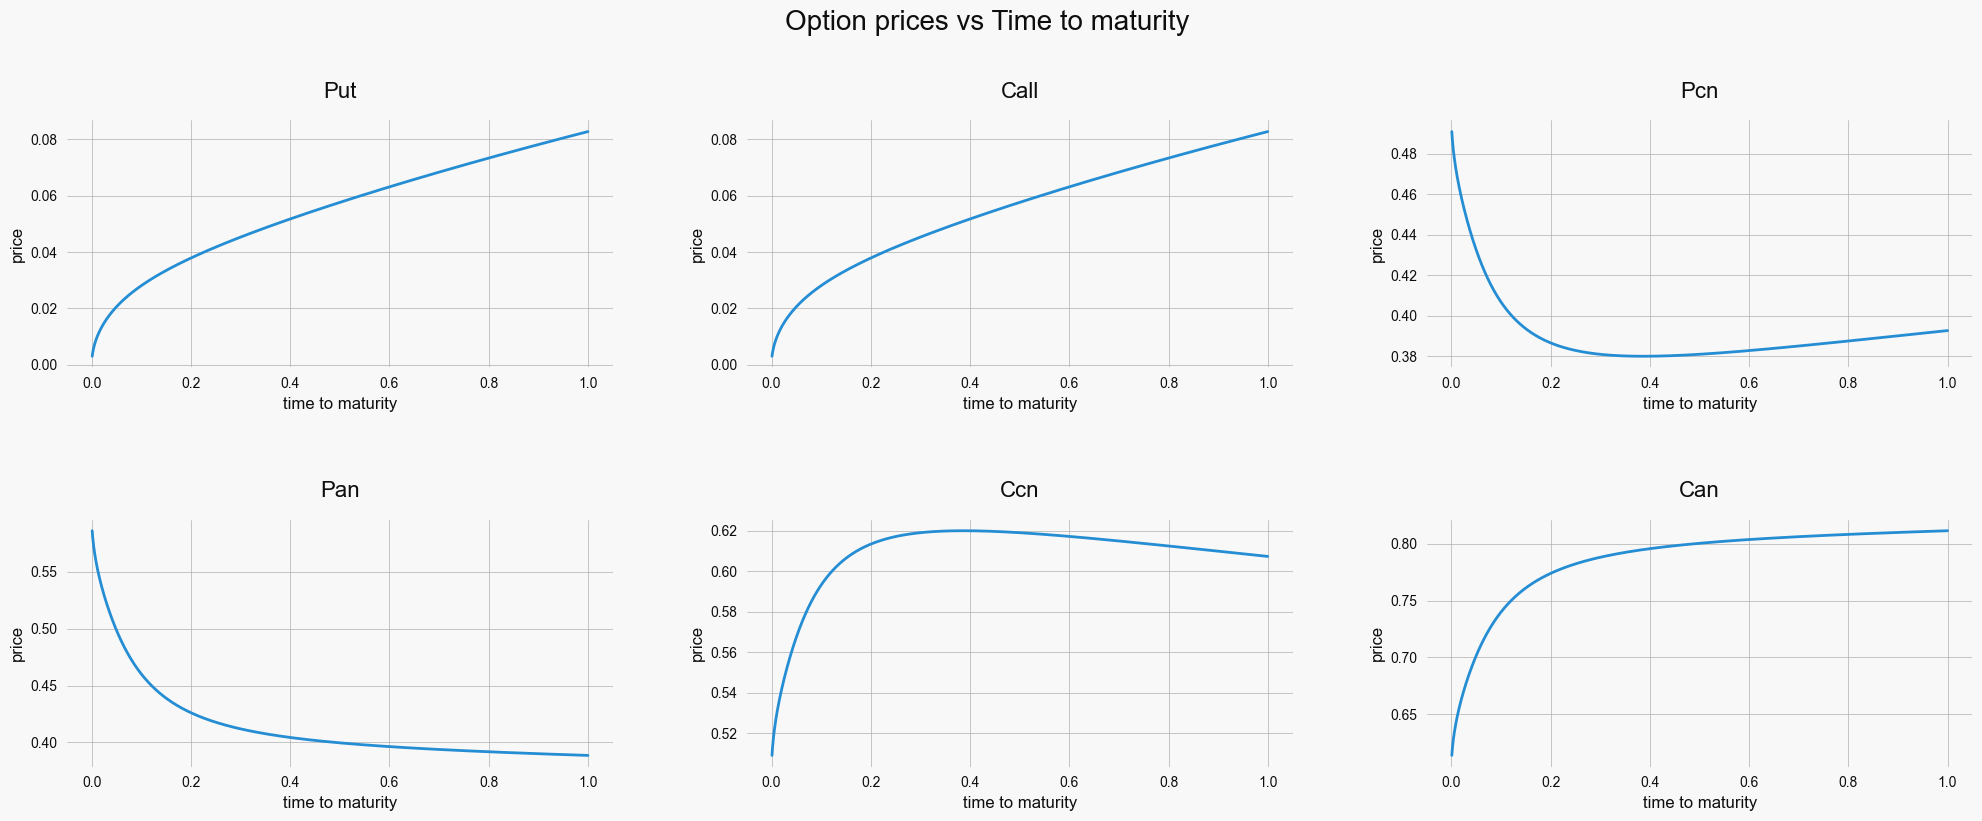

In [ ]:
# option price vs time to maturity, K = S0 fixed
taus = np.linspace(0.001, 1.0, 1001)
prices_from_maturity = {name: np.zeros(len(taus)) for name in option_names}

for i, tau in enumerate(taus):
    res = price_options_vec(np.array([S0]), np.array([nu0]), tau, lam, nu_bar, eta, rho, K, Xc)
    for name in option_names:
        prices_from_maturity[name][i] = res[name][0]

df_curves = pd.DataFrame({"tau": taus, **prices_from_maturity})
df_curves.to_csv("prices_from_maturity.csv", index = False)

fig, axes = plt.subplots(2, 3, figsize = (20, 8))
axes = axes.flatten()

for i, name in enumerate(option_names):
    ax = axes[i]
    ax.plot(taus, prices_from_maturity[name], color = colors[0], lw = 2)
    ax.set_title(name, fontsize = 16, pad = 16)
    ax.set_xlabel('time to maturity', fontsize = 12)
    ax.set_ylabel('price', fontsize = 12)

plt.suptitle('Option prices vs Time to maturity', fontsize = 20, y = 1.02)
plt.tight_layout(h_pad = 5, w_pad = 5)
plt.savefig("prices_from_maturity.png", dpi = 150, bbox_inches = 'tight')
plt.show()

# QE instead of FE

In [ ]:
PSI_C = 1.5  # switching threshold, Andersen Section 3.2.3

def qe_step(nu_prev, dt, lam, nu_bar, eta, rng):
    """
    QE step for CIR variance process.
    Source: Andersen (2006), Section 3.2, eq. 17-18, 23-30
    A single uniform U_V drives both branches (Z_V = Phi^{-1}(U_V)), so each step uses one
    random number for the variance; this makes antithetic / common-random-number variants easy
    """
    e = np.exp(-lam * dt)
    h = 1 - e

    # eq. 17-18
    m = nu_bar + (nu_prev - nu_bar) * e
    s2 = (eta ** 2 * h / lam) * (nu_prev * e + 0.5 * nu_bar * h)
    psi = s2 / m ** 2

    # single uniform draw -- used for BOTH cases
    U_V = rng.uniform(size = nu_prev.shape)

    # Case 1: psi <= psi_c, quadratic scheme eq. 27-28, 23
    b2 = np.where(psi <= PSI_C, np.maximum(2 / psi - 1 + np.sqrt(np.maximum((2 / psi) * (2 / psi - 1), 0.0)), 0.0), 0.0)
    a = np.where(psi <= PSI_C, m / (1 + b2), 0.0)
    Z_V = scipy_norm.ppf(U_V)                        # Z_V = Phi^{-1}(U_V)
    case1 = a * (np.sqrt(b2) + Z_V) ** 2

    # Case 2: psi > psi_c, exponential scheme eq. 29-30, 25
    p = np.where(psi > PSI_C, (psi - 1) / (psi + 1), 0.0)
    beta = np.where(psi > PSI_C, (1 - p) / m, 1.0)
    case2 = np.where(U_V > p, np.log((1 - p) / np.maximum(1 - U_V, 1e-30)) / beta, 0.0)

    return np.where(psi <= PSI_C, case1, case2)

In [17]:
def qe_heston_step_no_mc(nu_prev, ln_S_prev, dt, lam, nu_bar, eta, rho, rng):
    """QE step (without martingale correction). Source: Andersen eq. 33"""
    g1, g2 = 0.5, 0.5

    nu_next = qe_step(nu_prev, dt, lam, nu_bar, eta, rng)

    K0 = -rho * lam * nu_bar / eta * dt
    K1 = g1 * dt * (rho * lam / eta - 0.5) - rho / eta
    K2 = g2 * dt * (rho * lam / eta - 0.5) + rho / eta
    K3 = g1 * dt * (1 - rho ** 2)
    K4 = g2 * dt * (1 - rho ** 2)

    U = rng.uniform(size = nu_prev.shape)
    Z = scipy_norm.ppf(U)    # Z independent of the variance draw (Andersen eq. 33)

    ln_S_next = (ln_S_prev + K0 + K1 * nu_prev + K2 * nu_next + np.sqrt(np.maximum(K3 * nu_prev + K4 * nu_next, 0.0)) * Z)
    return nu_next, ln_S_next


rng_qe2 = np.random.default_rng(seed=42)
nu_t  = np.full(N_traj, nu0)
lnS_t = np.full(N_traj, np.log(S0))

print("QE Martingale check E[S(t_j)]:")
for j, tm in enumerate(t_months):
    for _ in range(step_per_month):
        nu_t, lnS_t = qe_heston_step_no_mc(nu_t, lnS_t, dt, lam, nu_bar, eta, rho, rng_qe2)
    mean = np.exp(lnS_t).mean()
    std = np.exp(lnS_t).std() / np.sqrt(N_traj)
    print(f"t = {tm:.2f}: {mean:.4f} +/- {2*std:.4f}")
    
print("No martingale correction needed, since results are already good")

QE Martingale check E[S(t_j)]:
t = 0.08: 1.2001 +/- 0.0004
t = 0.17: 1.2000 +/- 0.0006
t = 0.25: 1.2001 +/- 0.0007
t = 0.33: 1.2003 +/- 0.0009
t = 0.42: 1.2008 +/- 0.0010
t = 0.50: 1.2009 +/- 0.0011
t = 0.58: 1.2008 +/- 0.0011
t = 0.67: 1.2008 +/- 0.0012
t = 0.75: 1.2007 +/- 0.0013
t = 0.83: 1.2004 +/- 0.0014
t = 0.92: 1.2002 +/- 0.0014
t = 1.00: 1.2002 +/- 0.0015
No martingale correction needed, since results are already good


In [18]:
# Compare QE vs exact CIR: price Put option at T using both schemes
rng_cmp = np.random.default_rng(seed = 42)

# Exact CIR (already implemented)
nu_exact, I_exact, S_exact = simulate_heston(nu0, lam, nu_bar, eta, rho, S0, dt, N_steps, N_traj, rng_cmp)

# QE simulation
rng_cmp2 = np.random.default_rng(seed = 42)
nu_qe = np.full(N_traj, nu0)
lnS_qe = np.full(N_traj, np.log(S0))

for _ in range(N_steps):
    nu_qe, lnS_qe = qe_heston_step_no_mc(nu_qe, lnS_qe, dt, lam, nu_bar, eta, rho, rng_cmp2)

S_qe_T = np.exp(lnS_qe)

# Compare Put prices at T
put_exact = np.maximum(K - S_exact[-1], 0)
put_qe = np.maximum(K - S_qe_T, 0)

mean_exact = put_exact.mean(); std_exact = put_exact.std() / np.sqrt(N_traj)
mean_qe = put_qe.mean(); std_qe = put_qe.std() / np.sqrt(N_traj)

print(f"Fourier reference: {ref_prices['Put']:.6f}")
print(f"Exact CIR MC Put: {mean_exact:.6f} +/- {2 * std_exact:.6f}")
print(f"QE MC Put: {mean_qe:.6f} +/- {2 * std_qe:.6f}")
print(f"Difference: {abs(mean_exact - mean_qe):.2e}")

Fourier reference: 0.082747
Exact CIR MC Put: 0.082870 +/- 0.001075
QE MC Put: 0.082906 +/- 0.001074
Difference: 3.60e-05


In [57]:
rng_av3 = np.random.default_rng(seed=42)

# Pre-generate ALL nu paths first, then apply antithetic only to Z
# xi_V = rng_av3.standard_normal((N_steps, N_traj))
xi_Z = rng_av3.standard_normal((N_steps, N_traj))

# Simulate nu (shared)
nu_sh = np.zeros((N_steps+1, N_traj))
nu_sh[0] = nu0
for n in range(N_steps):
    nu_sh[n + 1] = cir_exact_step(nu_sh[n], dt, lam, nu_bar, eta, rng_av3)

# S original and antithetic with shared nu
lnS_pos = np.full(N_traj, np.log(S0))
lnS_ant = np.full(N_traj, np.log(S0))

for n in range(N_steps):
    DI = 0.5 * (nu_sh[n] + nu_sh[n + 1])*dt
    d_nu = nu_sh[n + 1] - nu_sh[n]
    base = (-0.5 * DI + (rho / eta) * (d_nu - lam * (nu_bar * dt - DI)))
    vol = np.sqrt(np.maximum((1 - rho ** 2) * DI, 0.0))
    lnS_pos = lnS_pos + base + vol * xi_Z[n]
    lnS_ant = lnS_ant + base - vol * xi_Z[n]   # antithetic: -Z

put_pos = np.maximum(K - np.exp(lnS_pos), 0)
put_ant = np.maximum(K - np.exp(lnS_ant), 0)
put_av  = 0.5 * (put_pos + put_ant)

std_std = put_pos.std() / np.sqrt(N_traj)
std_av  = put_av.std()  / np.sqrt(N_traj)

print(f"FE standard: {put_pos.mean():.6f}, std = {std_std:.6f}")
print(f"FE antithetic: {put_av.mean():.6f}, std = {std_av:.6f}")
print(f"Reduction: {std_std / std_av:.3f}x")
print(f"Fourier: {ref_prices['Put']:.6f}")

FE standard: 0.082870, std = 0.000537
FE antithetic: 0.082761, std = 0.000430
Reduction: 1.249x
Fourier: 0.082747


In [58]:
rng_qe_av = np.random.default_rng(seed = 123)

# Pre-generate U_V for nu (shared between original and antithetic)
U_V_all = rng_qe_av.uniform(size=(N_steps, N_traj))
U_Z_all = rng_qe_av.uniform(size=(N_steps, N_traj))

# Simulate nu using pre-generated U_V
def qe_step_from_U(nu_prev, U_V, dt, lam, nu_bar, eta):
    e = np.exp(-lam * dt)
    h = 1 - e
    m = nu_bar + (nu_prev - nu_bar) * e
    s2 = (eta ** 2 * h / lam) * (nu_prev * e + 0.5 * nu_bar * h)
    psi = s2 / m ** 2

    b2 = np.where(psi <= PSI_C, np.maximum(2 / psi - 1 + np.sqrt(np.maximum((2 / psi) * (2 / psi - 1), 0.0)), 0.0), 0.0)
    a = np.where(psi <= PSI_C, m / (1 + b2), 0.0)
    Z_V = scipy_norm.ppf(U_V)
    case1 = a * (np.sqrt(b2) + Z_V) ** 2
    p = np.where(psi > PSI_C, (psi - 1) / (psi + 1), 0.0)
    beta = np.where(psi > PSI_C, (1 - p) / m, 1.0)
    case2 = np.where(U_V > p, np.log((1 - p) / np.maximum(1 - U_V, 1e-300)) / beta, 0.0)
    return np.where(psi <= PSI_C, case1, case2)

# Simulate shared nu path
nu_qe_sh = np.zeros((N_steps + 1, N_traj))
nu_qe_sh[0] = nu0

for n in range(N_steps):
    nu_qe_sh[n+1] = qe_step_from_U(nu_qe_sh[n], U_V_all[n], dt, lam, nu_bar, eta)

# S original and antithetic
lnS_pos = np.full(N_traj, np.log(S0))
lnS_ant = np.full(N_traj, np.log(S0))

g1, g2 = 0.5, 0.5
K0 = -rho * lam * nu_bar / eta * dt
K1 = g1 * dt * (rho * lam / eta - 0.5) - rho / eta
K2 = g2 * dt * (rho * lam / eta - 0.5) + rho / eta
K3 = g1 * dt * (1 - rho ** 2)
K4 = g2 * dt * (1 - rho ** 2)

for n in range(N_steps):
    nu_n, nu_n1 = nu_qe_sh[n], nu_qe_sh[n+1]
    base = K0 + K1 * nu_n + K2 * nu_n1
    vol = np.sqrt(np.maximum(K3 * nu_n + K4 * nu_n1, 0.0))
    Z = scipy_norm.ppf(U_Z_all[n])
    lnS_pos = lnS_pos + base + vol * Z
    lnS_ant = lnS_ant + base - vol * Z

put_pos = np.maximum(K - np.exp(lnS_pos), 0)
put_ant = np.maximum(K - np.exp(lnS_ant), 0)
put_av  = 0.5 * (put_pos + put_ant)

std_std = put_pos.std() / np.sqrt(N_traj)
std_av = put_av.std() / np.sqrt(N_traj)

print(f"QE standard: {put_pos.mean():.6f}, std = {std_std:.6f}")
print(f"QE antithetic: {put_av.mean():.6f}, std = {std_av:.6f}")
print(f"Reduction: {std_std/std_av:.3f}x")
print(f"Fourier: {ref_prices['Put']:.6f}")

QE standard: 0.082967, std = 0.000538
QE antithetic: 0.082944, std = 0.000431
Reduction: 1.248x
Fourier: 0.082747


In [53]:
# Euler discretization bias test
# Shows that Euler scheme requires many steps to converge
# As a result - motivation for using exact CIR and QE instead

rng_euler = np.random.default_rng(seed=42)

print("Euler scheme bias test:")
print(f"{'N_steps':>10} | {'E[S(T)]':>10} | {'±2σ':>10}")
print("-" * 36)

for N_test in [252, 500, 1000, 2000]:
    dt_test = T / N_test
    xi_Y = rng_euler.standard_normal((N_test, N_traj))
    xi_Z = rng_euler.standard_normal((N_test, N_traj))

    nu_e = np.zeros((N_test + 1, N_traj))
    I_e = np.zeros((N_test + 1, N_traj))
    nu_e[0] = nu0

    for n in range(N_test):
        nu_hat = nu_e[n] + lam*(nu_bar - nu_e[n]) * dt_test + eta * np.sqrt(nu_e[n] * dt_test) * xi_Y[n]
        nu_e[n + 1] = np.maximum(nu_hat, 0.0)
        I_e[n + 1] = I_e[n] + 0.5*(nu_e[n] + nu_e[n + 1]) * dt_test

    S_e = np.zeros((N_test + 1, N_traj))
    S_e[0] = S0
    for n in range(N_test):
        DI = I_e[n + 1] - I_e[n]
        d_nu = nu_e[n + 1] - nu_e[n]
        X = (-0.5 * DI + (rho / eta) * (d_nu - lam * (nu_bar * dt_test - DI)) + np.sqrt(np.maximum((1 - rho ** 2) * DI, 0.0)) * xi_Z[n])
        S_e[n + 1] = S_e[n] * np.exp(X)

    mean = S_e[-1].mean()
    std = S_e[-1].std() / np.sqrt(N_traj)
    print(f"{N_test:>10} | {mean:>10.5f} | {2*std:>10.5f}")

print(f"\nExact CIR (N = 252): E[S(T)] = {S_sim[-1].mean():.4f} +/- {2 * S_sim[-1].std() / np.sqrt(N_traj):.4f}")

Euler scheme bias test:
   N_steps |    E[S(T)] |        ±2σ
------------------------------------
       252 |    1.17985 |    0.00160
       500 |    1.18172 |    0.00159
      1000 |    1.18521 |    0.00157
      2000 |    1.18758 |    0.00156

Exact CIR (N = 252): E[S(T)] = 1.2002 +/- 0.0015
